In [58]:
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from datetime import datetime
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, make_scorer
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [26]:
import pandas as pd
# Charger les fichiers CSV
train_resampled = pd.read_csv("train_resampled.csv")
test = pd.read_csv("test.csv")

df_unlabeled = pd.read_csv("df_unlabeled.csv")

In [28]:
print(train_resampled.dtypes)

sessions                   float64
drives                     float64
total_sessions             float64
n_days_after_onboarding    float64
total_navigations_fav1     float64
driven_km_drives           float64
duration_minutes_drives    float64
activity_days              float64
driving_days               float64
total_navigations          float64
km_per_session             float64
label                        int64
dtype: object


In [30]:
print(len(test))

2860


In [32]:
# Séparer les features et les labels
X_train_resampled = train_resampled.drop('label', axis=1)
y_train_resampled = train_resampled['label']

X_test = test.drop('label', axis=1)
y_test = test['label']

# 1. Régression Logistique

In [34]:
# Modèle de base
model = LogisticRegression(random_state=42, solver='saga')

# Nouvelle grille élargie
param_grid = {
    'penalty': ['l1', 'l2', 'elasticnet', 'none'],  # régularisation
    'C': [0.01, 0.1, 1, 10, 100],                   # régularisation
    'l1_ratio': [0, 0.5, 1],                         # pour elasticnet uniquement
    'max_iter': [500, 1000, 2000],                   # itérations max
    'tol': [1e-4, 1e-3, 1e-2],                       # tolérance de convergence
    'class_weight': [None, 'balanced']               # gestion du déséquilibre
}

# Plusieurs métriques
scoring = {
    'accuracy': 'accuracy',
    'f1': make_scorer(f1_score)
}

# GridSearch avec refit sur F1-score
grid_search_RL = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring=scoring,
    refit='f1',
    n_jobs=-1,
    verbose=2
)

# Entraînement
grid_search_RL.fit(X_train_resampled, y_train_resampled)

# Résultats
print("Meilleurs paramètres :", grid_search_RL.best_params_)
print("Meilleur F1-score (CV) :", grid_search_RL.best_score_)

results = grid_search_RL.cv_results_
print("Meilleure accuracy (CV) :", max(results['mean_test_accuracy']))

# Prédiction sur test
best_model = grid_search_RL.best_estimator_
y_pred = best_model.predict(X_test)


Fitting 5 folds for each of 1080 candidates, totalling 5400 fits
Meilleurs paramètres : {'C': 0.01, 'class_weight': None, 'l1_ratio': 0, 'max_iter': 500, 'penalty': 'l1', 'tol': 0.0001}
Meilleur F1-score (CV) : 0.7070022229895738
Meilleure accuracy (CV) : 0.6976089266737514


Test Accuracy: 0.666083916083916
Test F1-score: 0.43591258121677495
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.65      0.76      2353
           1       0.31      0.73      0.44       507

    accuracy                           0.67      2860
   macro avg       0.61      0.69      0.60      2860
weighted avg       0.81      0.67      0.70      2860



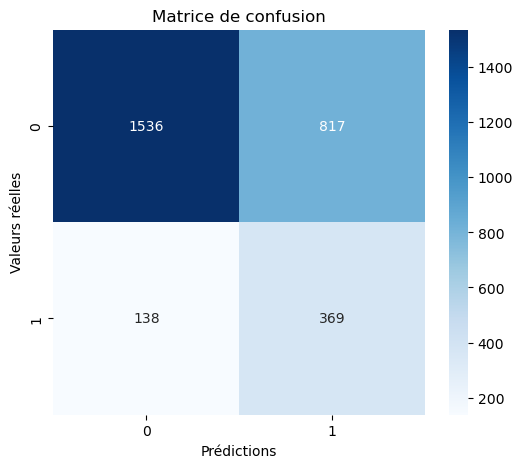

In [79]:
import matplotlib.pyplot as plt 
import seaborn as sns
print("Test Accuracy:", accuracy_score(y_test, y_pred))

# F1-score (classification binaire)
print("Test F1-score:", f1_score(y_test, y_pred, average='binary'))

# Rapport détaillé (précision, rappel, f1-score par classe)
print("Classification Report:\n", classification_report(y_test, y_pred))

# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()


# 2. SVM

In [81]:
# Modèle de base
model = SVC(random_state=42)

# Grille des hyperparamètres à tester
param_grid = {
    'C': [0.1, 1, 10, 100],            # Régularisation
    'kernel': ['linear', 'rbf'],       # Noyau linéaire et gaussien
    'gamma': ['scale', 'auto'],        # Paramètre noyau (pour rbf)
    'class_weight': [None, 'balanced'] # Gestion du déséquilibre
}

# Définir plusieurs scores pour évaluer le modèle
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'f1': make_scorer(f1_score, average='binary')
}

# GridSearch avec validation croisée 5-fold, évaluation multi-métriques
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring=scoring,
    refit='f1',          # Choisir le meilleur modèle selon f1-score
    cv=5,
    verbose=2,
    n_jobs=-1
)

# Entraînement sur tes données équilibrées
grid_search.fit(X_train_resampled, y_train_resampled)

# Meilleurs paramètres selon le f1-score
print("Meilleurs paramètres :", grid_search.best_params_)
print(f"Meilleur F1-score (CV) : {grid_search.best_score_:.4f}")

# Meilleur modèle pour prédiction
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Affichage des scores sur test
from sklearn.metrics import accuracy_score, f1_score
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test F1-score:", f1_score(y_test, y_pred, average='binary'))

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Meilleurs paramètres : {'C': 100, 'class_weight': None, 'gamma': 'scale', 'kernel': 'rbf'}
Meilleur F1-score (CV) : 0.8115
Test Accuracy: 0.6863636363636364
Test F1-score: 0.35514018691588783


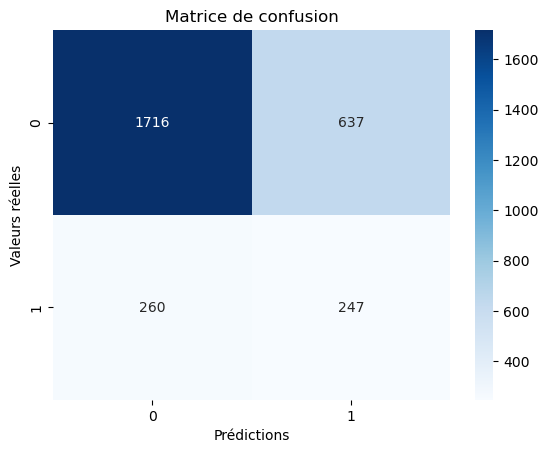

In [83]:
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()


In [85]:
print("\nRapport de classification :")
print(classification_report(y_test, y_pred))


Rapport de classification :
              precision    recall  f1-score   support

           0       0.87      0.73      0.79      2353
           1       0.28      0.49      0.36       507

    accuracy                           0.69      2860
   macro avg       0.57      0.61      0.57      2860
weighted avg       0.76      0.69      0.72      2860



In [38]:
print(f"\nExactitude : {accuracy_score(y_test, y_pred):.2f}")


Exactitude : 0.69


In [40]:
print(len(y_test))

2860


In [42]:
print(len(X_train_resampled))

18852


# Random Forest

In [53]:

# Initialiser le modèle
rf = RandomForestClassifier(random_state=42)

# Définir la grille des hyperparamètres
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# GridSearchCV
grid_search = GridSearchCV(estimator=rf,
                           param_grid=param_grid,
                           cv=5,
                           scoring='f1',
                           n_jobs=-1,
                           verbose=1)

# Entraînement
grid_search.fit(X_train_resampled, y_train_resampled)

# Meilleurs paramètres
print("Meilleurs paramètres :", grid_search.best_params_)

# Prédictions
y_pred = grid_search.predict(X_test)

# Rapport de classification
print(classification_report(y_test, y_pred))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Meilleurs paramètres : {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
              precision    recall  f1-score   support

           0       0.86      0.79      0.83      2353
           1       0.30      0.42      0.35       507

    accuracy                           0.73      2860
   macro avg       0.58      0.61      0.59      2860
weighted avg       0.76      0.73      0.74      2860



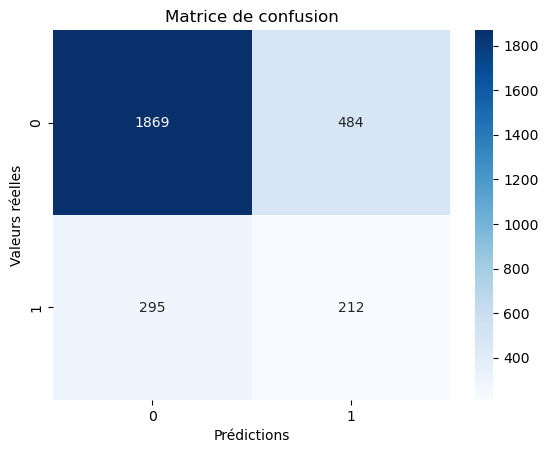

In [55]:
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()


In [57]:
print(f"Meilleur F1-score (CV) : {grid_search.best_score_:.4f}")

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test F1-score:", f1_score(y_test, y_pred, average='binary'))

Meilleur F1-score (CV) : 0.8098
Test Accuracy: 0.7276223776223776
Test F1-score: 0.35245220282626766


# KNN

In [13]:
# Définir les valeurs à tester avec GridSearch pour KNN
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Initialiser le classificateur KNN
knn = KNeighborsClassifier()

# Utiliser GridSearchCV
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_resampled, y_train_resampled)

# Afficher les meilleurs paramètres
print("Meilleurs hyperparamètres :", grid_search.best_params_)

# Prédictions avec le meilleur modèle
best_knn = grid_search.best_estimator_
y_pred = best_knn.predict(X_test)

# Évaluation
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Classification Report :\n", classification_report(y_test, y_pred))

Meilleurs hyperparamètres : {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}
Accuracy : 0.6580419580419581
Classification Report :
               precision    recall  f1-score   support

           0       0.86      0.69      0.77      2353
           1       0.26      0.49      0.34       507

    accuracy                           0.66      2860
   macro avg       0.56      0.59      0.55      2860
weighted avg       0.76      0.66      0.69      2860



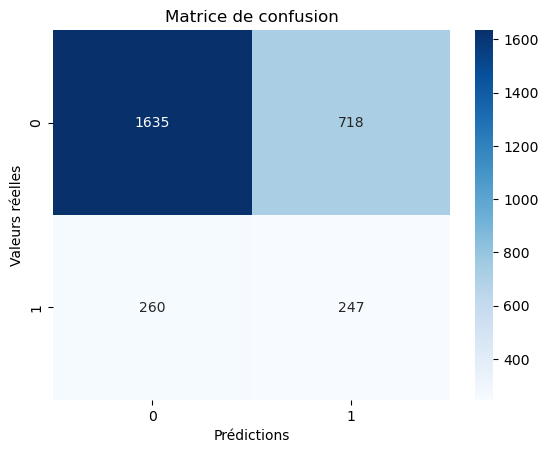

In [17]:
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()

In [19]:
print(f"Meilleur F1-score (CV) : {grid_search.best_score_:.4f}")

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test F1-score:", f1_score(y_test, y_pred, average='binary'))

Meilleur F1-score (CV) : 0.8368
Test Accuracy: 0.6580419580419581
Test F1-score: 0.33559782608695654


# NaiveBayes

In [24]:
# Définir les hyperparamètres à tester
param_grid = {
    'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
}

# Initialisation du modèle Naive Bayes
gnb = GaussianNB()

# GridSearchCV
grid_search = GridSearchCV(gnb, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_resampled, y_train_resampled)

# Meilleurs paramètres
print("Meilleurs hyperparamètres :", grid_search.best_params_)

# Évaluation
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Classification Report :\n", classification_report(y_test, y_pred))

Meilleurs hyperparamètres : {'var_smoothing': 1e-09}
Accuracy : 0.6454545454545455
Classification Report :
               precision    recall  f1-score   support

           0       0.92      0.62      0.74      2353
           1       0.30      0.75      0.43       507

    accuracy                           0.65      2860
   macro avg       0.61      0.69      0.59      2860
weighted avg       0.81      0.65      0.69      2860



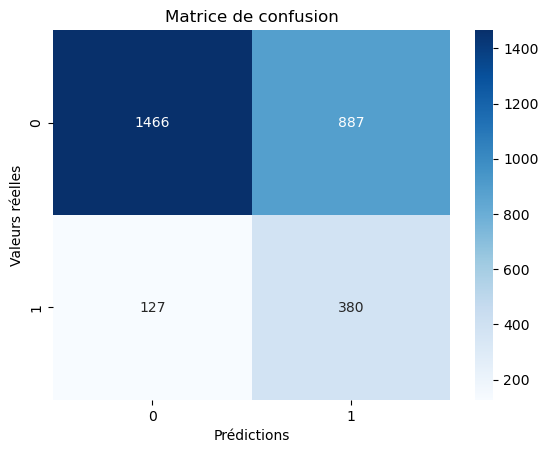

In [26]:
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()

In [27]:
print(f"Meilleur F1-score (CV) : {grid_search.best_score_:.4f}")

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test F1-score:", f1_score(y_test, y_pred, average='binary'))

Meilleur F1-score (CV) : 0.6930
Test Accuracy: 0.6454545454545455
Test F1-score: 0.42841037204058624


In [ ]:
X_unlabeled = df_unlabeled.drop('label', axis=1)  # données non étiquetées

In [62]:
# Prédictions avec probabilités
y_unlabeled_proba = grid_search_RL.predict_proba(X_unlabeled)

# Étiquettes prédites
y_unlabeled_pred = grid_search_RL.predict(X_unlabeled)

In [64]:
# Calculer la confiance maximale pour chaque prédiction
confidence = np.max(y_unlabeled_proba, axis=1)

# Seuil de confiance
threshold = 0.9
high_confidence_mask = confidence >= threshold

# Garder uniquement les échantillons très sûrs
X_pseudo = X_unlabeled[high_confidence_mask]
y_pseudo = y_unlabeled_pred[high_confidence_mask]

In [68]:
print(X_pseudo)

Empty DataFrame
Columns: [sessions, drives, total_sessions, n_days_after_onboarding, total_navigations_fav1, driven_km_drives, duration_minutes_drives, activity_days, driving_days, total_navigations, km_per_session]
Index: []


In [48]:
# Concaténer les nouvelles données pseudo-étiquetées
X_labeled = np.concatenate([X_train_resampled, X_pseudo])
y_labeled = np.concatenate([y_train_resampled, y_pseudo])
# Supprimer les exemples utilisés des données non étiquetées
X_unlabeled = X_unlabeled[~high_confidence_mask]

In [50]:
grid_search_RL.fit(X_labeled, y_labeled)

Fitting 5 folds for each of 1080 candidates, totalling 5400 fits


GridSearchCV(cv=5, estimator=LogisticRegression(random_state=42, solver='saga'),
             n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10, 100],
                         'class_weight': [None, 'balanced'],
                         'l1_ratio': [0, 0.5, 1], 'max_iter': [500, 1000, 2000],
                         'penalty': ['l1', 'l2', 'elasticnet', 'none'],
                         'tol': [0.0001, 0.001, 0.01]},
             refit='f1',
             scoring={'accuracy': 'accuracy',
                      'f1': make_scorer(f1_score, response_method='predict')},
             verbose=2)

In [60]:
# Paramètres
threshold = 0.9
max_iterations = 10
min_new_samples = 5  # stop si trop peu de nouvelles pseudo-étiquettes

for iteration in range(max_iterations):
    print(f"\n🔁 Iteration {iteration+1}")

    # Étape 1 : entraînement sur les données étiquetées
    grid_search_RL.fit(X_labeled, y_labeled)

    # Étape 2 : prédiction avec probabilités
    y_unlabeled_proba = grid_search_RL.predict_proba(X_unlabeled)
    y_unlabeled_pred = grid_search_RL.predict(X_unlabeled)

    # Étape 3 : confiance
    confidence = np.max(y_unlabeled_proba, axis=1)
    high_confidence_mask = confidence >= threshold

    n_new = np.sum(high_confidence_mask)
    print(f"  ✅ {n_new} pseudo-labels avec confiance >= {threshold}")

    # Vérifier si on continue
    if n_new < min_new_samples:
        print("  ⛔ Trop peu de nouveaux exemples, arrêt du self-training.")
        break

    # Étape 4 : garder les bons exemples
    X_pseudo = X_unlabeled[high_confidence_mask]
    y_pseudo = y_unlabeled_pred[high_confidence_mask]

    # Étape 5 : concaténer avec les données existantes
    X_labeled = np.concatenate([X_train_resampled, X_pseudo])
    y_labeled = np.concatenate([y_train_resampled, y_pseudo])

    # Étape 6 : retirer les pseudo-étiquettes utilisées
    X_unlabeled = X_unlabeled[~high_confidence_mask]

    # Facultatif : afficher le nombre restant
    print(f"  📉 Il reste {len(X_unlabeled)} données non étiquetées.")

print("\n✅ Self-training terminé.")


🔁 Iteration 1
Fitting 5 folds for each of 1080 candidates, totalling 5400 fits
  ✅ 0 pseudo-labels avec confiance >= 0.9
  ⛔ Trop peu de nouveaux exemples, arrêt du self-training.

✅ Self-training terminé.


In [70]:
y_pred = grid_search_RL.predict(X_test)
print(f"Meilleur F1-score (CV) : {grid_search_RL.best_score_:.4f}")

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test F1-score:", f1_score(y_test, y_pred, average='binary'))

Meilleur F1-score (CV) : 0.7070
Test Accuracy: 0.666083916083916
Test F1-score: 0.43591258121677495


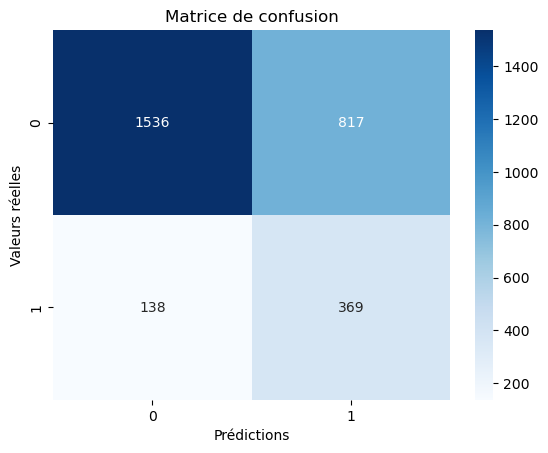

In [72]:
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()